In [4]:
data = pd.read_csv('chembl.csv' , sep=';')
data.head()

,Assay ChEMBL ID,Assay Type,Description,Organism,Target ChEMBL ID,Compounds,Compounds.1,Activities,BAO Format ID,BAO Format,...,Journal,Volume,First Page,Last Page,Assay Parameters,Assay Classification L1,Assay Classification L2,Assay Classification L3,Variant Sequence Accession,Variant Sequence Mutation
0,CHEMBL1267242,F,Antiplasmodial activity against Plasmodium fal...,Plasmodium falciparum,CHEMBL364,2,2,2,BAO_0000218,organism-based format,...,Nat Chem Biol,5,765.0,771.0,NaN,NaN,NaN,NaN,NaN,NaN
1,CHEMBL667619,B,Inhibitory activity against triple mutant dihy...,Plasmodium falciparum,CHEMBL1939,40,40,40,BAO_0000357,single protein format,...,J Med Chem,47,345.0,354.0,NaN,NaN,NaN,NaN,NaN,NaN
2,CHEMBL1266370,F,Antiplasmodial activity against Plasmodium fal...,Plasmodium falciparum,CHEMBL364,2,2,2,BAO_0000218,organism-based format,...,Nat Chem Biol,5,765.0,771.0,NaN,NaN,NaN,NaN,NaN,NaN
3,CHEMBL2345245,F,Antimalarial activity against schizont stage o...,Plasmodium falciparum,CHEMBL364,7,7,7,BAO_0000218,organism-based format,...,J Med Chem,56,31.0,45.0,NaN,NaN,NaN,NaN,NaN,NaN
4,CHEMBL1268649,F,Antigametocyte activity against drug-resistant...,Plasmodium falciparum,CHEMBL364,1,1,1,BAO_0000218,organism-based format,...,Antimicrob Agents Chemother,54,1334.0,1337.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
filtered_data = data[(data["Assay Type"] == "B") | (data["Assay Type"] == "F")]
print("Applying assay type filter only:", filtered_data.shape[0])

filtered2 = data[(data["Assay Type"] == "B") | (data["Assay Type"] == "F")] & (data["BAO Format"]=="BAO_0000357")
print("applying assay type and BAO format filters:", filtered2.shape[0])

Applying assay type filter only: 17360


In [8]:
biding_function = data[(data["BAO Format"] == "BAO_0000357") & (data["Assay Type"] == "F")]
print("Functional assay type and BAO format:", biding_function.shape[0])

Functional assay type and BAO format: 0


# Exploratory Data Analysis - ChEMBL Drug Targets

This notebook performs comprehensive EDA on the filtered ChEMBL dataset (Assay Type B only).

In [9]:
# Load the filtered dataset
drugs_targets = pd.read_csv('chembl_drugs_targets.csv', sep=';')
print("Dataset shape:", drugs_targets.shape)
print("\nFirst few rows:")
drugs_targets.head()

Dataset shape: (2022, 14)

First few rows:


,Assay ChEMBL ID,Assay Type,Description,Organism,Target ChEMBL ID,BAO Format ID,BAO Format,Confidence Score,Confidence Label,Strain,Source,Tax ID,Variant Sequence Accession,Variant Sequence Mutation
0,CHEMBL667619,B,Inhibitory activity against triple mutant dihy...,Plasmodium falciparum,CHEMBL1939,BAO_0000357,single protein format,8,8 - Homologous single protein target assigned,NaN,Scientific Literature,5833.0,NaN,NaN
1,CHEMBL909252,B,Inhibition of Tween 20-induced beta-hematin fo...,Plasmodium falciparum,CHEMBL1923,BAO_0000357,single protein format,9,9 - Direct single protein target assigned,NaN,Scientific Literature,5833.0,NaN,NaN
2,CHEMBL1043308,B,Inhibition of His-tagged Plasmodium falciparum...,Plasmodium falciparum,CHEMBL612545,BAO_0000019,assay format,0,0 - Default value - Target unknown or has yet ...,NaN,Scientific Literature,5833.0,NaN,NaN
3,CHEMBL941962,B,Inhibition of Plasmodium falciparum W2 recombi...,Plasmodium falciparum,CHEMBL5800,BAO_0000357,single protein format,9,9 - Direct single protein target assigned,W2,Scientific Literature,5833.0,NaN,NaN
4,CHEMBL1114762,B,Inhibition of Plasmodium falciparum plasmepsin...,Plasmodium falciparum,CHEMBL4414,BAO_0000019,assay format,9,9 - Direct single protein target assigned,NaN,Scientific Literature,5833.0,NaN,NaN


In [10]:
# Basic Dataset Information
print("Dataset Info:")
print("="*60)
drugs_targets.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 2022 entries, 0 to 2021
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Assay ChEMBL ID             2022 non-null   str    
 1   Assay Type                  2022 non-null   str    
 2   Description                 2022 non-null   str    
 3   Organism                    1900 non-null   str    
 4   Target ChEMBL ID            2022 non-null   str    
 5   BAO Format ID               2022 non-null   str    
 6   BAO Format                  2022 non-null   str    
 7   Confidence Score            2022 non-null   int64  
 8   Confidence Label            2022 non-null   str    
 9   Strain                      168 non-null    str    
 10  Source                      2022 non-null   str    
 11  Tax ID                      1891 non-null   float64
 12  Variant Sequence Accession  26 non-null     str    
 13  Variant Sequence Mutation   31

In [ ]:
# Missing Values Analysis
print("Missing Values:")
print("="*60)
missing = drugs_targets.isnull().sum()
missing_pct = (missing / len(drugs_targets)) * 100
missing_df = pd.DataFrame({
    'Column': missing.index,
    'Missing Count': missing.values,
    'Missing %': missing_pct.values
})
print(missing_df[missing_df['Missing Count'] > 0].to_string())

In [ ]:
# Unique Values Count
print("\nUnique Values per Column:")
print("="*60)
unique_counts = drugs_targets.nunique().sort_values(ascending=False)
for col, count in unique_counts.items():
    print(f"{col:.<45} {count:>5}")

In [ ]:
# Confidence Label Distribution
print("\nConfidence Label Distribution:")
print("="*60)
confidence_dist = drugs_targets['Confidence Label'].value_counts()
print(confidence_dist)
print(f"\nTotal: {confidence_dist.sum()}")

In [ ]:
# Top 15 Organisms
print("\nTop 15 Organisms:")
print("="*60)
organism_counts = drugs_targets['Organism'].value_counts().head(15)
print(organism_counts)

In [ ]:
# BAO Format Distribution
print("\nBAO Format Distribution:")
print("="*60)
bao_dist = drugs_targets['BAO Format'].value_counts()
print(bao_dist)

In [ ]:
# Source Distribution
print("\nSource Distribution:")
print("="*60)
source_dist = drugs_targets['Source'].value_counts()
print(source_dist)

In [ ]:
# Confidence Score Statistics
print("\nConfidence Score Statistics:")
print("="*60)
print(drugs_targets['Confidence Score'].describe())

## Visualizations

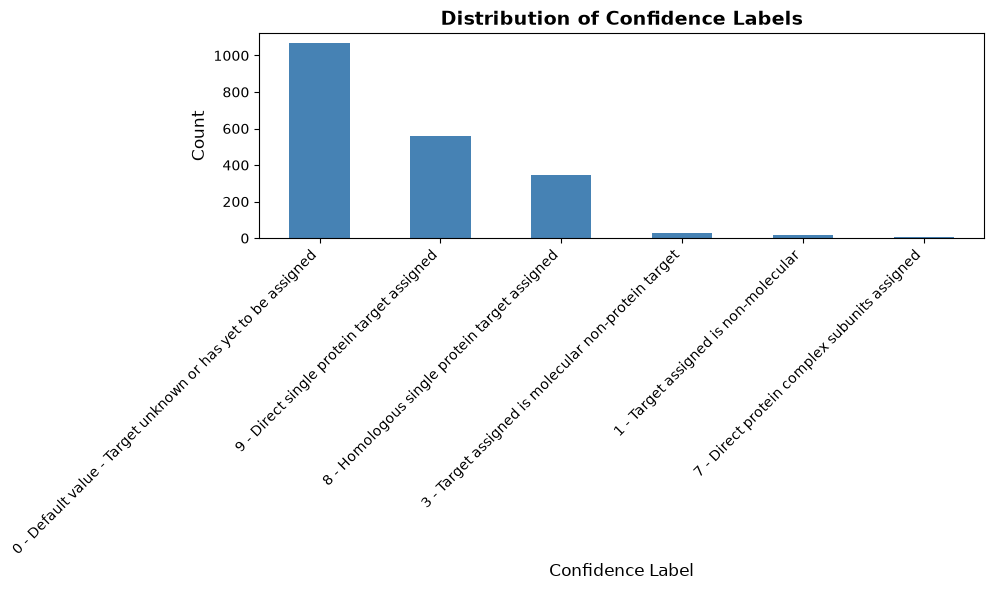

In [13]:
# Confidence Label Distribution - Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
confidence_data = drugs_targets['Confidence Label'].value_counts()
confidence_data.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Distribution of Confidence Labels', fontsize=14, fontweight='bold')
ax.set_xlabel('Confidence Label', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

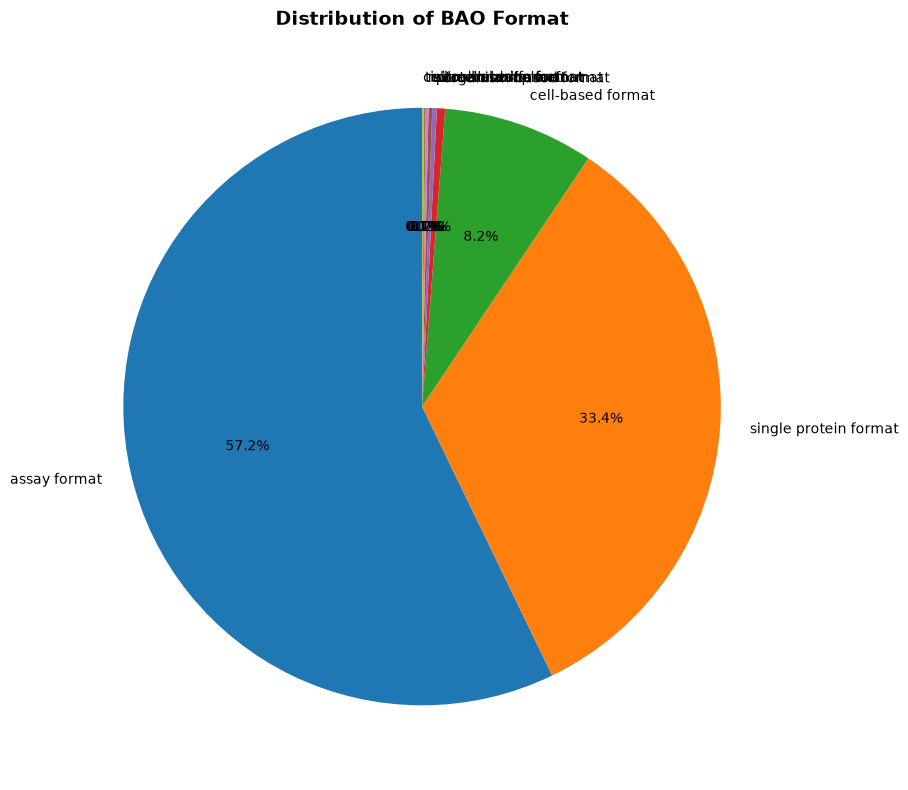

In [14]:
# BAO Format Distribution - Pie Chart
fig, ax = plt.subplots(figsize=(10, 8))
bao_data = drugs_targets['BAO Format'].value_counts()
bao_data.plot(kind='pie', ax=ax, autopct='%1.1f%%', startangle=90)
ax.set_title('Distribution of BAO Format', fontsize=14, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

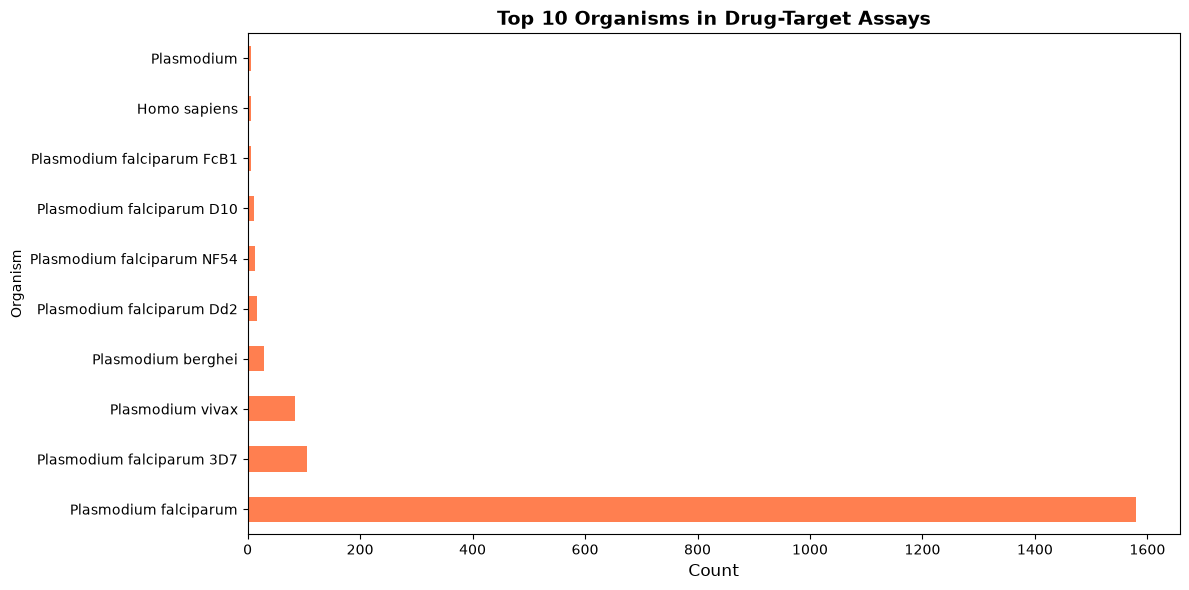

In [15]:
# Top 10 Organisms - Bar Chart
fig, ax = plt.subplots(figsize=(12, 6))
organism_data = drugs_targets['Organism'].value_counts().head(10)
organism_data.plot(kind='barh', ax=ax, color='coral')
ax.set_title('Top 10 Organisms in Drug-Target Assays', fontsize=14, fontweight='bold')
ax.set_xlabel('Count', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Confidence Score Distribution - Histogram
fig, ax = plt.subplots(figsize=(10, 6))
drugs_targets['Confidence Score'].value_counts().sort_index().plot(kind='bar', ax=ax, color='lightblue', edgecolor='black')
ax.set_title('Distribution of Confidence Score Values', fontsize=14, fontweight='bold')
ax.set_xlabel('Confidence Score', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
plt.tight_layout()
plt.show()

## Summary Statistics

In [11]:
# Overall Summary
print("\n" + "="*60)
print("OVERALL DATASET SUMMARY")
print("="*60)
print(f"Total Records: {len(drugs_targets):,}")
print(f"Total Columns: {len(drugs_targets.columns)}")
print(f"Total Unique Targets: {drugs_targets['Target ChEMBL ID'].nunique():,}")
print(f"Total Unique Organisms: {drugs_targets['Organism'].nunique()}")
print(f"Total Unique Assays: {drugs_targets['Assay ChEMBL ID'].nunique():,}")
print(f"Total Data Sources: {drugs_targets['Source'].nunique()}")
print(f"\nAssay Type Distribution (All): F={len(data[data['Assay Type'] == 'F']):,}, B={len(drugs_targets):,}")
print("="*60)


OVERALL DATASET SUMMARY
Total Records: 2,022
Total Columns: 14
Total Unique Targets: 118
Total Unique Organisms: 25
Total Unique Assays: 2,022
Total Data Sources: 7

Assay Type Distribution (All): F=15,338, B=2,022


**Uniprod proteins plasmodium falciparum**

In [5]:
uniprod = pd.read_csv('uniprotkb_organism_name_Plasmodium_falc_2026_06_19.tsv' , sep='\t')
print("\nUniprot Data Shape:", uniprod.shape)


Uniprot Data Shape: (23379, 15)


In [6]:
#number of null values in uniprot dataset
print("\nMissing Values in Uniprot Dataset:")
missing_uni = uniprod.isnull().sum()
missing_uni_pct = (missing_uni / len(uniprod)) * 100
print(missing_uni)
print(missing_uni_pct)


Missing Values in Uniprot Dataset:
Entry                      0
Reviewed                   0
Entry Name                 0
Protein names              0
Gene Names              2140
Organism                   0
Length                     0
Interacts with         23350
Binding site           22803
Active site            22994
Function [CC]          20651
Catalytic activity     22042
EC number              21320
Activity regulation    23264
Site                   23291
dtype: int64
Entry                   0.000000
Reviewed                0.000000
Entry Name              0.000000
Protein names           0.000000
Gene Names              9.153514
Organism                0.000000
Length                  0.000000
Interacts with         99.875957
Binding site           97.536250
Active site            98.353223
Function [CC]          88.331409
Catalytic activity     94.281193
EC number              91.192951
Activity regulation    99.508106
Site                   99.623594
dtype: float64


In [7]:
interpro = pd.read_csv('protein-sequences.tsv' , sep='\t')
print(interpro.head() )

    Accession Source Database  \
0  A0A023JGI3      unreviewed   
1  A0A023JGI4      unreviewed   
2  A0A023JGI5      unreviewed   
3  A0A023JGI6      unreviewed   
4  A0A023JGI7      unreviewed   

                                              Name  Tax ID  \
0  Duffy-antigen binding domain-containing protein    5833   
1  Duffy-antigen binding domain-containing protein    5833   
2  Duffy-antigen binding domain-containing protein    5833   
3  Duffy-antigen binding domain-containing protein    5833   
4  Duffy-antigen binding domain-containing protein    5833   

                Tax Name  Length  
0  Plasmodium falciparum     131  
1  Plasmodium falciparum     124  
2  Plasmodium falciparum     136  
3  Plasmodium falciparum     121  
4  Plasmodium falciparum     122  


In [18]:
#verify unique values in the interpro dataset
print("\nUnique  Accession Values in InterPro Dataset:")   
unique_interpro = interpro["Accession"].nunique()
print(unique_interpro)
print("InterPro total unique accessions:", interpro.shape[0])

#verify unique values of uniprot proteins with uniprot dataset
print("\nUnique values of uniprot proteins with uniprot dataset:")  
unique_uniprot = uniprod["Entry"].nunique()
print("Total length of uniprot dataset:", uniprod.shape[0])
print("Unique values of uniprot proteins:", unique_uniprot)


Unique  Accession Values in InterPro Dataset:
17308
InterPro total unique accessions: 17308

Unique values of uniprot proteins with uniprot dataset:
Total length of uniprot dataset: 23379
Unique values of uniprot proteins: 23379


ENTRY COMPARISON ANALYSIS
Total Entries in Uniprot Dataset: 23379
Total Entries in InterPro Dataset: 17308

Common Entries: 17273
Unique to Uniprot: 6106
Unique to InterPro: 35


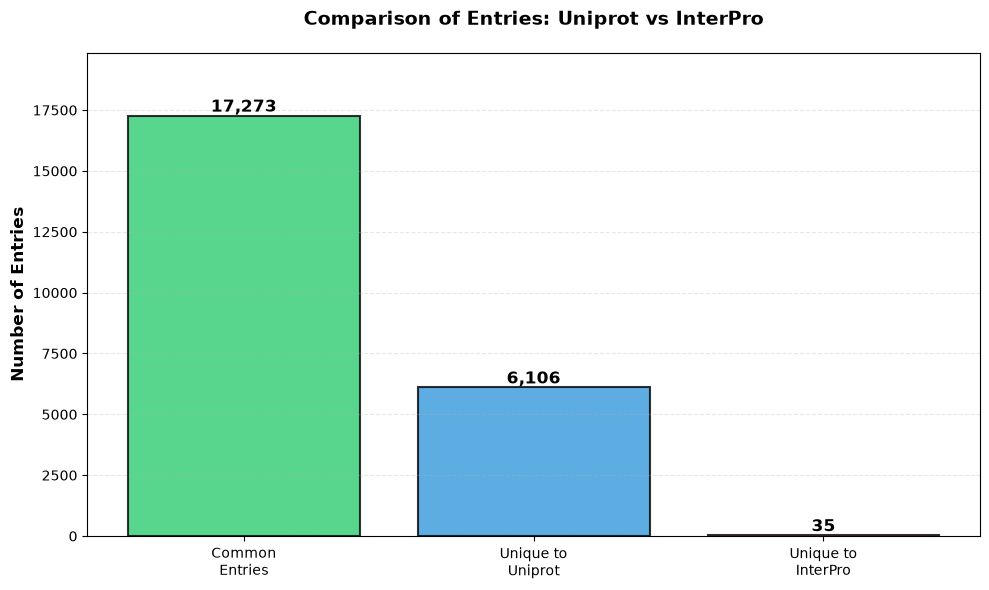

In [17]:
# Verifying common and unique entries between the two datasets
# Dataset 1: Uniprot (Entry field)
# Dataset 2: InterPro (Accession field)

unipro_entry_set = set(uniprod['Entry'])
protein_accession_set = set(interpro['Accession'])

# Calculate different entry sets
common_entries = unipro_entry_set.intersection(protein_accession_set)
unique_to_uniprot = unipro_entry_set - protein_accession_set
unique_to_interpro = protein_accession_set - unipro_entry_set

# Print summary statistics
print("="*60)
print("ENTRY COMPARISON ANALYSIS")
print("="*60)
print(f"Total Entries in Uniprot Dataset: {len(unipro_entry_set)}")
print(f"Total Entries in InterPro Dataset: {len(protein_accession_set)}")
print(f"\nCommon Entries: {len(common_entries)}")
print(f"Unique to Uniprot: {len(unique_to_uniprot)}")
print(f"Unique to InterPro: {len(unique_to_interpro)}")
print("="*60)

# Create visualization
fig, ax = plt.subplots(figsize=(10, 6))

categories = ['Common\nEntries', 'Unique to\nUniprot', 'Unique to\nInterPro']
counts = [len(common_entries), len(unique_to_uniprot), len(unique_to_interpro)]
colors = ['#2ecc71', '#3498db', "#fc9589"]

bars = ax.bar(categories, counts, color=colors, edgecolor='black', linewidth=1.5, alpha=0.8)

# Add value labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('Comparison of Entries: Uniprot vs InterPro', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Number of Entries', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


In [19]:
# Merge uniprot and interpro datasets for Plasmodium falciparum
# Step 1: Filter uniprot for Plasmodium falciparum
uniprot_pf = uniprod[uniprod['Organism'].str.contains('Plasmodium falciparum', case=False, na=False)].copy()
uniprot_pf = uniprot_pf[['Entry', 'Protein names', 'Length']].copy()
uniprot_pf['Entry_lower'] = uniprot_pf['Entry'].str.lower()

print("="*60)
print("DATASET MERGING - Plasmodium falciparum")
print("="*60)
print(f"Uniprot entries for P. falciparum: {len(uniprot_pf)}")

# Step 2: Filter interpro for Plasmodium falciparum
print("len before filtering interpro:", len(interpro))
interpro_pf = interpro[interpro['Tax Name'].str.contains('Plasmodium falciparum', case=False, na=False)].copy()
interpro_pf = interpro_pf[['Accession', 'Name', 'Length']].copy()
interpro_pf.columns = ['Entry', 'Protein names', 'Length']  # Rename to match uniprot
interpro_pf['Entry_lower'] = interpro_pf['Entry'].str.lower()

print(f"InterPro entries for P. falciparum: {len(interpro_pf)}")

# Step 3: Identify common and unique entries (case-insensitive)
uniprot_entries_lower = set(uniprot_pf['Entry_lower'])
interpro_entries_lower = set(interpro_pf['Entry_lower'])

common_entries_set = uniprot_entries_lower.intersection(interpro_entries_lower)
unique_uniprot = uniprot_entries_lower - common_entries_set
unique_interpro = interpro_entries_lower - common_entries_set

print(f"\nCommon entries: {len(common_entries_set)}")
print(f"Unique to Uniprot: {len(unique_uniprot)}")
print(f"Unique to InterPro: {len(unique_interpro)}")

# Step 4: Merge datasets with source information
merged_list = []

# Add all uniprot entries (common and unique to uniprot)
for idx, row in uniprot_pf.iterrows():
    entry_lower = row['Entry_lower']
    source = 'common' if entry_lower in common_entries_set else 'uniprot'
    merged_list.append({
        'Entry': row['Entry'],
        'Protein names': row['Protein names'],
        'Length': row['Length'],
        'Source': source
    })

# Add all unique interpro entries (not in uniprot)
interpro_unique_count = 0
for idx, row in interpro_pf.iterrows():
    entry_lower = row['Entry_lower']
    if entry_lower not in uniprot_entries_lower:  # Only add if NOT in uniprot
        merged_list.append({
            'Entry': row['Entry'],
            'Protein names': row['Protein names'],
            'Length': row['Length'],
            'Source': 'interpro'
        })
        interpro_unique_count += 1

# Create merged dataframe
merged_df = pd.DataFrame(merged_list)
merged_df = merged_df.sort_values('Entry').reset_index(drop=True)

# Save to CSV
merged_df.to_csv('uniprot_interpro_plasmodium_falciparum_merged.csv', index=False)

print(f"\n{'='*60}")
print("MERGE RESULTS")
print(f"{'='*60}")
print(f"Total merged entries: {len(merged_df)}")
print(f"Common entries (both datasets): {len(merged_df[merged_df['Source'] == 'common'])}")
print(f"Uniprot only: {len(merged_df[merged_df['Source'] == 'uniprot'])}")
print(f"InterPro only (verified): {interpro_unique_count}")
print(f"\nSource breakdown:")
print(merged_df['Source'].value_counts())
print(f"\nFirst 10 rows of merged dataset:")
print(merged_df.head(10).to_string())
print(f"\nLast 10 rows (InterPro unique entries):")
print(merged_df[merged_df['Source'] == 'interpro'].head(10).to_string())
print(f"\nMerged dataset saved to: 'uniprot_interpro_plasmodium_falciparum_merged.csv'")
print("="*60)


DATASET MERGING - Plasmodium falciparum
Uniprot entries for P. falciparum: 23379
len before filtering interpro: 17308
InterPro entries for P. falciparum: 17273

Common entries: 17273
Unique to Uniprot: 6106
Unique to InterPro: 0

MERGE RESULTS
Total merged entries: 23379
Common entries (both datasets): 17273
Uniprot only: 6106
InterPro only (verified): 0

Source breakdown:
Source
common     17273
uniprot     6106
Name: count, dtype: int64

First 10 rows of merged dataset:
        Entry                   Protein names  Length  Source
0  A0A023JGI3  Erythrocyte membrane protein 1     131  common
1  A0A023JGI4  Erythrocyte membrane protein 1     124  common
2  A0A023JGI5  Erythrocyte membrane protein 1     136  common
3  A0A023JGI6  Erythrocyte membrane protein 1     121  common
4  A0A023JGI7  Erythrocyte membrane protein 1     122  common
5  A0A023JGI8  Erythrocyte membrane protein 1     126  common
6  A0A023JGI9  Erythrocyte membrane protein 1     114  common
7  A0A023JGJ0  Erythrocyte 

Found 50 .pdb.gz files

Extracted 40 unique protein names from PDP dataset
Saved to 'pdp_proteins_2025.csv'

First 10 protein names:
                          Protein_Name
                110_c4 fab heavy chain
                110_c4 fab light chain
                ankyrin-repeat protein
                 bromodomain protein 1
         bromodomain protein, putative
choline-phosphate cytidylyltransferase
 cholinephosphate cytidylyltransferase
              circumsporozoite protein
                 cysteine--trna ligase
        erythrocyte membrane protein 1

PDP vs UNIPROT COMPARISON ANALYSIS (Case-Insensitive)
Total Proteins in PDP Dataset: 40
Total Entries in Uniprot Dataset: 4878

Common Entries: 21
Unique to PDP: 19
Unique to Uniprot: 4857


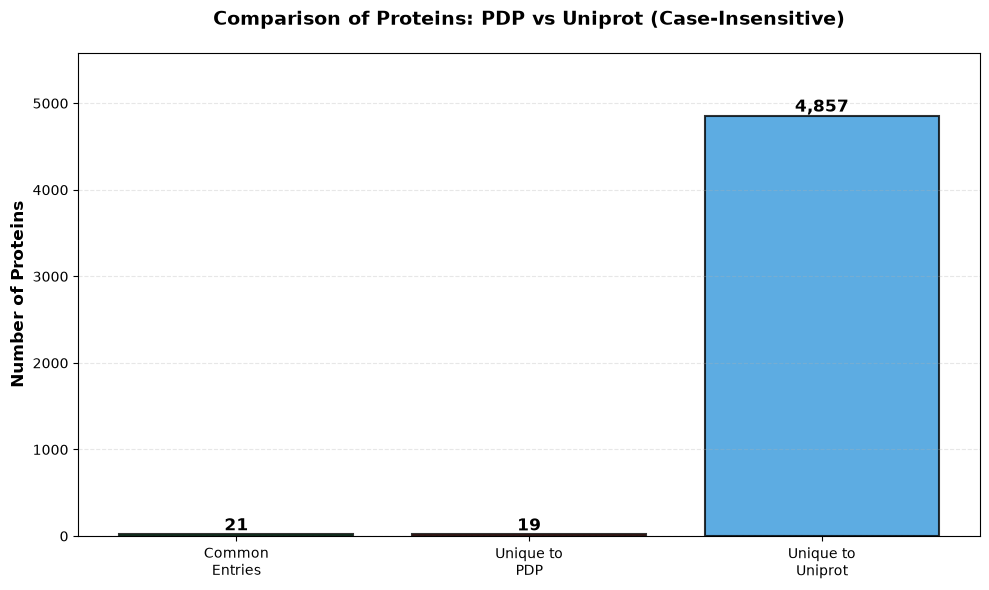

In [11]:
import os
import gzip
import re
from pathlib import Path

# Path to PDP dataset
path_pdp = 'pdp_dataset_2025'

# Extract protein names from .pdb.gz files
protein_names_pdp = set()
pdp_files = []

if os.path.exists(path_pdp):
    for file in os.listdir(path_pdp):
        if file.endswith('.pdb.gz'):
            pdp_files.append(file)
            file_path = os.path.join(path_pdp, file)
            
            try:
                with gzip.open(file_path, 'rt') as f:
                    content = f.read()
                    # Extract protein names from COMPND lines (MOLECULE: field)
                    compnd_matches = re.findall(r'COMPND\s+.*?MOLECULE:\s*(.+?)\s*;', content, re.MULTILINE)
                    for name in compnd_matches:
                        if name.strip():
                            # Normalize to lowercase for comparison
                            protein_names_pdp.add(name.strip().lower())
                    
                    # Also extract from HEADER lines as fallback
                    headers = re.findall(r'HEADER\s+(.+?)\s+\d{4}-\d{2}-\d{2}', content, re.MULTILINE)
                    for header in headers:
                        if header.strip():
                            # Normalize to lowercase for comparison
                            protein_names_pdp.add(header.strip().lower())
            except Exception as e:
                print(f"Error processing {file}: {e}")
    
    print(f"Found {len(pdp_files)} .pdb.gz files")
else:
    print(f"Directory {path_pdp} not found")

# Save protein names to CSV
pdp_df = pd.DataFrame({'Protein_Name': sorted(list(protein_names_pdp))})
pdp_df.to_csv('pdp_proteins_2025.csv', index=False)
print(f"\nExtracted {len(protein_names_pdp)} unique protein names from PDP dataset")
print(f"Saved to 'pdp_proteins_2025.csv'")
print(f"\nFirst 10 protein names:")
print(pdp_df.head(10).to_string(index=False))

# Compare PDP proteins with Uniprot dataset
# Normalize both to lowercase for comparison
uniprot_entries = set(uniprod['Protein names'].str.lower())
pdp_protein_set = set(protein_names_pdp)

common_entries_pdp = pdp_protein_set.intersection(uniprot_entries)
unique_to_pdp = pdp_protein_set - uniprot_entries
unique_to_uniprot = uniprot_entries - pdp_protein_set

# Print comparison statistics
print("\n" + "="*60)
print("PDP vs UNIPROT COMPARISON ANALYSIS (Case-Insensitive)")
print("="*60)
print(f"Total Proteins in PDP Dataset: {len(pdp_protein_set)}")
print(f"Total Entries in Uniprot Dataset: {len(uniprot_entries)}")
print(f"\nCommon Entries: {len(common_entries_pdp)}")
print(f"Unique to PDP: {len(unique_to_pdp)}")
print(f"Unique to Uniprot: {len(unique_to_uniprot)}")
print("="*60)

# Create visualization
fig, ax = plt.subplots(figsize=(10, 6))

categories = ['Common\nEntries', 'Unique to\nPDP', 'Unique to\nUniprot']
counts = [len(common_entries_pdp), len(unique_to_pdp), len(unique_to_uniprot)]
colors = ['#2ecc71', '#e74c3c', '#3498db']

bars = ax.bar(categories, counts, color=colors, edgecolor='black', linewidth=1.5, alpha=0.8)

# Add value labels on bars
for bar, count in zip(bars, counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{count:,}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('Comparison of Proteins: PDP vs Uniprot (Case-Insensitive)', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Number of Proteins', fontsize=12, fontweight='bold')
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()


In [ ]:
collected_assays = pd.read_csv("pf_bioassays.csv")
collected_assays.head()